# Laboratory Exercise 1: Food Delivery

City Delivery is a delivery service that brings meals from restaurants across Macedonia to the door. Its pages are a stored snapshot in `data/site`, and the setup serves them from this machine, so every request stays on the local loopback address. The orders are synthetic and describe no real restaurant, courier, or customer.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [1]:
%pip install playwright

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import re
import threading
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urljoin, urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup, Tag
from playwright.async_api import async_playwright
from scipy import stats
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
# Every random step draws from this generator, so a rerun gives the same result.
rng = np.random.default_rng(2026)

In [3]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [4]:
# Every path is a file under the site directory.
class Service(SimpleHTTPRequestHandler):
    extensions_map = {
        **SimpleHTTPRequestHandler.extensions_map,
        ".html": "text/html; charset=utf-8",
    }

    def log_message(self, format: str, *args: object) -> None:
        pass


# Port 0 lets the system choose a free port, so a second running notebook never collides.
server = ThreadingHTTPServer(("127.0.0.1", 0), partial(Service, directory=DATA / "site"))
threading.Thread(target=server.serve_forever, daemon=True).start()
BASE = f"http://127.0.0.1:{server.server_port}/"
BASE

'http://127.0.0.1:59809/'

## Task 1: Collect the Orders

The service lists its delivered orders across several pages, and the first one is `catalogue/page-1.html` under `BASE`. Collect every order into a table named `orders`, with one row per order and these columns:

- `order_id`, the identifier of the order,
- `restaurant`, `cuisine`, and `city`,
- `distance` and `unit`, the distance from the restaurant to the door and the unit it is quoted in, exactly as the order states them,
- `minutes`, the minutes the delivery took,
- `slot`, `weather`, `payment`, and `rating`, the stars out of 5 that the customer gave, and
- `by_restaurant`, which is true when the restaurant delivered the order itself and false when a courier of the service did.

An order that does not state a field has a missing value in that column. Report how many orders the service lists and over how many pages they are spread.

In [5]:
url = BASE + "catalogue/page-1.html"

response = requests.get(url, timeout=10)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

cards = soup.select("article.order")

print("Status:", response.status_code)
print("Order on page 1:", len(cards))
print("First order ID:", cards[0]["data-id"])


Status: 200
Order on page 1: 12
First order ID: 310069


In [6]:
print(cards[0].prettify())

<article class="card order" data-id="310069" id="order-310069">
 <h2 class="title">
  <a href="#order-310069">
   Salad Bowl
  </a>
 </h2>
 <p class="place">
  <span class="cuisine">
   Salad
  </span>
  ,
  <span class="city">
   Skopje
  </span>
 </p>
 <p class="delivery figure">
  Delivered in 23 minutes.
 </p>
 <p class="summary">
  A trip of 5.0 km from the restaurant to the door.
 </p>
 <ul class="tags">
  <li class="slot">
   Late night
  </li>
  <li class="weather">
   Clear
  </li>
  <li class="payment">
   Cash
  </li>
  <li class="rating">
   Rated 5 of 5
  </li>
 </ul>
 <p class="courier muted">
  Delivered by a City Delivery courier.
 </p>
</article>



In [7]:
card = cards[0]

order_id = int(card["data-id"])
restaurant = card.select_one(".title").get_text(strip=True)
cuisine = card.select_one(".cuisine").get_text(strip=True)
city = card.select_one(".city").get_text(strip=True)

print("Order ID:", order_id)
print("Restaurant:", restaurant)
print("Cuisine:", cuisine)
print("City:", city)

Order ID: 310069
Restaurant: Salad Bowl
Cuisine: Salad
City: Skopje


In [8]:
# Delivery time
delivery = card.select_one(".delivery.figure")

delivery_text = delivery.get_text(strip=True) if delivery else ""
minutes_match = re.search(r"(\d+)\s+minutes", delivery_text)

minutes = int(minutes_match.group(1)) if minutes_match else None

# Distance and unit
summary = card.select_one(".summary")
summary_text = summary.get_text(strip=True) if summary else ""

distance_match = re.search(r"(\d[\d .]*)\s+(km|m)\b", summary_text)

distance = float(distance_match.group(1).replace(" ", "")) if distance_match else None
unit = distance_match.group(2) if distance_match else None

print("Minutes:", minutes)
print("Distance:", distance)
print("Unit:", unit)

Minutes: 23
Distance: 5.0
Unit: km


In [9]:
# Extract slot, weather and payment
slot = card.select_one(".slot").get_text(strip=True)
weather = card.select_one(".weather").get_text(strip=True)
payment = card.select_one(".payment").get_text(strip=True)

# Extract rating
rating_element = card.select_one(".rating")

rating_text = rating_element.get_text(strip=True) if rating_element else ""
rating_match = re.search(r"Rated (\d+) of 5", rating_text)

rating = int(rating_match.group(1)) if rating_match else None

# Check who delivered the order
courier_element = card.select_one(".courier")
courier_text = courier_element.get_text(strip=True) if courier_element else ""

by_restaurant = "by the restaurant" in courier_text.lower() if courier_text else None

print("Slot:", slot)
print("Weather:", weather)
print("Payment:", payment)
print("Rating:", rating)
print("By restaurant:", by_restaurant)

Slot: Late night
Weather: Clear
Payment: Cash
Rating: 5
By restaurant: False


In [10]:
def parse_order(card):

    def optional_text(selector):
        element = card.select_one(selector)
        return element.get_text(strip=True) if element else None

    # Delivery time
    delivery_text = optional_text(".delivery.figure") or ""
    minutes_match = re.search(r"(\d+)\s+minutes", delivery_text)

    minutes = int(minutes_match.group(1)) if minutes_match else None

    # Distance
    summary_text = optional_text(".summary") or ""
    distance_match = re.search(r"(\d[\d .]*)\s+(km|m)\b", summary_text)

    distance = float(distance_match.group(1).replace(" ", "")) if distance_match else None
    unit = distance_match.group(2) if distance_match else None

    # Rating
    rating_text = optional_text(".rating") or ""
    rating_match = re.search(r"Rated\s+(\d+)\s+of\s+5", rating_text)

    rating = int(rating_match.group(1)) if rating_match else None

    # Courier
    courier_text = optional_text(".courier")

    by_restaurant = (
        "by the restaurant" in courier_text.lower()
        if courier_text else None
    )

    return {
        "order_id": int(card["data-id"]),
        "restaurant": optional_text(".title"),
        "cuisine": optional_text(".cuisine"),
        "city": optional_text(".city"),
        "distance": distance,
        "unit": unit,
        "minutes": minutes,
        "slot": optional_text(".slot"),
        "weather": optional_text(".weather"),
        "payment": optional_text(".payment"),
        "rating": rating,
        "by_restaurant": by_restaurant
    }

In [11]:
# Start from the first page
page_url = BASE + "catalogue/page-1.html"

all_orders = []
page_count = 0

while page_url:

    response = requests.get(page_url, timeout=10)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    cards = soup.select("article.order")

    for card in cards:
        order = parse_order(card)
        all_orders.append(order)

    page_count += 1

    next_link = soup.select_one("a.next")

    if next_link:
        page_url = urljoin(page_url, next_link["href"])
    else:
        page_url = None

orders = pd.DataFrame(all_orders)

print("Total pages:", page_count)
print("Total orders:", len(orders))
print("Shape:", orders.shape)

orders.head()

Total pages: 16
Total orders: 192
Shape: (192, 12)


,order_id,restaurant,cuisine,city,distance,unit,minutes,slot,weather,payment,rating,by_restaurant
0,310069,Salad Bowl,Salad,Skopje,5.0,km,23.0,Late night,Clear,Cash,5.0,False
1,283894,Pizza House,Pizza,Skopje,3650.0,m,30.0,Lunch,Clear,Card,3.0,False
2,832866,Sushi Bar,Sushi,Skopje,4700.0,m,NaN,Lunch,Rain,Cash,3.0,True
3,582431,Home Kitchen,Traditional,Skopje,2.7,km,25.0,Lunch,Rain,Card,4.0,False
4,662069,Snack Corner,Small plates,Skopje,2.4,km,26.0,Late night,Clear,Card,4.0,True


In [12]:
print("Total orders:", len(orders))
print("Unique order IDs:", orders["order_id"].nunique())
print("Duplicate IDs:", orders["order_id"].duplicated().sum())

print("\nMissing values:")
print(orders.isna().sum())

Total orders: 192
Unique order IDs: 192
Duplicate IDs: 0

Missing values:
order_id          0
restaurant        0
cuisine           0
city              0
distance          0
unit              0
minutes          42
slot              0
weather           0
payment           0
rating           24
by_restaurant     0
dtype: int64


## Task 2: Add the Receipts

The home page of the service, `index.html` under `BASE`, points to a page of receipts. Collect every receipt the page holds, and add the items, the total, and the tip of each order to `orders`, so that every order appears exactly once. Name the result `df`.

Report how many receipts the page says it holds, how many you collected, and what you did about any receipt that would put an order in `df` more than once.

In [13]:
response = requests.get(BASE + "index.html")
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")

receipt_link = soup.select_one('a[href*="receipts"]')
receipt_url = urljoin(BASE, receipt_link["href"])

print("Receipts URL:", receipt_url)

receipt_response = requests.get(receipt_url)
receipt_response.raise_for_status()

receipt_soup = BeautifulSoup(receipt_response.text, "html.parser")

print("Status:", receipt_response.status_code)
print("Receipt rows:", len(receipt_soup.select("#receipts tr")))

Receipts URL: http://127.0.0.1:59809/receipts.html
Status: 200
Receipt rows: 0


In [29]:
match = re.search(r"const RECEIPTS\s*=\s*(\[.*?\]);", receipt_response.text, re.S)

receipts_data = json.loads(match.group(1))

print("Total receipts:", len(receipts_data))
print("First receipt:", receipts_data[0])

Total receipts: 193
First receipt: {'order_id': 695291, 'items': 3, 'total': 870, 'tip': 100}


In [30]:
receipts = pd.DataFrame(receipts_data)

print("Shape:", receipts.shape)
display(receipts.head())

Shape: (193, 4)


,order_id,items,total,tip
0,695291,3,870,100
1,893046,3,740,0
2,797860,3,640,50
3,294233,3,1180,260
4,466129,2,430,10


In [31]:
print("Total receipts:", len(receipts))
print("Unique order IDs:", receipts["order_id"].nunique())
print("Duplicate IDs:", receipts["order_id"].duplicated().sum())

display(receipts[receipts.duplicated(subset="order_id", keep=False)])

Total receipts: 193
Unique order IDs: 192
Duplicate IDs: 1


,order_id,items,total,tip
99,510546,4,1180,0
100,510546,4,1180,0


In [32]:
receipts = receipts.drop_duplicates(subset="order_id").reset_index(drop=True)

print("Receipts after removing duplicates:", len(receipts))
print("Duplicate IDs:", receipts["order_id"].duplicated().sum())

Receipts after removing duplicates: 192
Duplicate IDs: 0


In [33]:
df = orders.merge(receipts, on="order_id", how="left", validate="one_to_one")

print("Shape:", df.shape)
print("Missing receipts:", df["total"].isna().sum())

display(df.head())

Shape: (192, 15)
Missing receipts: 0


,order_id,restaurant,cuisine,city,distance,unit,minutes,slot,weather,payment,rating,by_restaurant,items,total,tip
0,310069,Salad Bowl,Salad,Skopje,5.0,km,23.0,Late night,Clear,Cash,5.0,False,2,770,0
1,283894,Pizza House,Pizza,Skopje,3650.0,m,30.0,Lunch,Clear,Card,3.0,False,4,860,60
2,832866,Sushi Bar,Sushi,Skopje,4700.0,m,NaN,Lunch,Rain,Cash,3.0,True,2,710,0
3,582431,Home Kitchen,Traditional,Skopje,2.7,km,25.0,Lunch,Rain,Card,4.0,False,3,1240,60
4,662069,Snack Corner,Small plates,Skopje,2.4,km,26.0,Late night,Clear,Card,4.0,True,2,450,30


In [34]:
print("Total orders:", len(df))
print("Unique order IDs:", df["order_id"].nunique())
print("Duplicate IDs:", df["order_id"].duplicated().sum())

print("\nMissing receipt values:")
print(df[["items", "total", "tip"]].isna().sum())

Total orders: 192
Unique order IDs: 192
Duplicate IDs: 0

Missing receipt values:
items    0
total    0
tip      0
dtype: int64


In [35]:
import os

print("Current working directory:", os.getcwd())
print("Notebook files:", [f for f in os.listdir() if f.endswith(".ipynb")])


Current working directory: C:\Users\Andrej\assignment\02-food-delivery
Notebook files: ['notebook.ipynb']


## Task 3: Describe the Orders

Answer each request below from `df`. Support each answer with the numbers that establish it, and with a figure wherever the request asks you to show something.

### 3.1 Column Types

Give every column of `df` a type that matches what it measures. The slots have a natural order, from lunch to late night, and the type of `slot` keeps it.

In [36]:
df["order_id"] = df["order_id"].astype("string")

for column in ["restaurant", "cuisine", "city", "unit", "weather", "payment"]:
    df[column] = df[column].astype("category")

df["slot"] = pd.Categorical(
    df["slot"],
    categories=["Lunch", "Dinner", "Late night"],
    ordered=True
)

df["by_restaurant"] = df["by_restaurant"].astype("boolean")

for column in ["distance", "minutes", "rating", "items", "total", "tip"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["items"] = df["items"].astype("Int64")
df["rating"] = df["rating"].astype("Int64")

print(df.dtypes)

order_id           string
restaurant       category
cuisine          category
city             category
distance          float64
unit             category
minutes           float64
slot             category
weather          category
payment          category
rating              Int64
by_restaurant     boolean
items               Int64
total               int64
tip                 int64
dtype: object


### 3.2 What Is Missing

Count the missing values in each column, show where they fall, and find out whether the absence of a value depends on another column.

,missing_count,missing_percent
order_id,0,0.00
restaurant,0,0.00
cuisine,0,0.00
city,0,0.00
distance,0,0.00
unit,0,0.00
minutes,42,21.88
slot,0,0.00
weather,0,0.00
payment,0,0.00


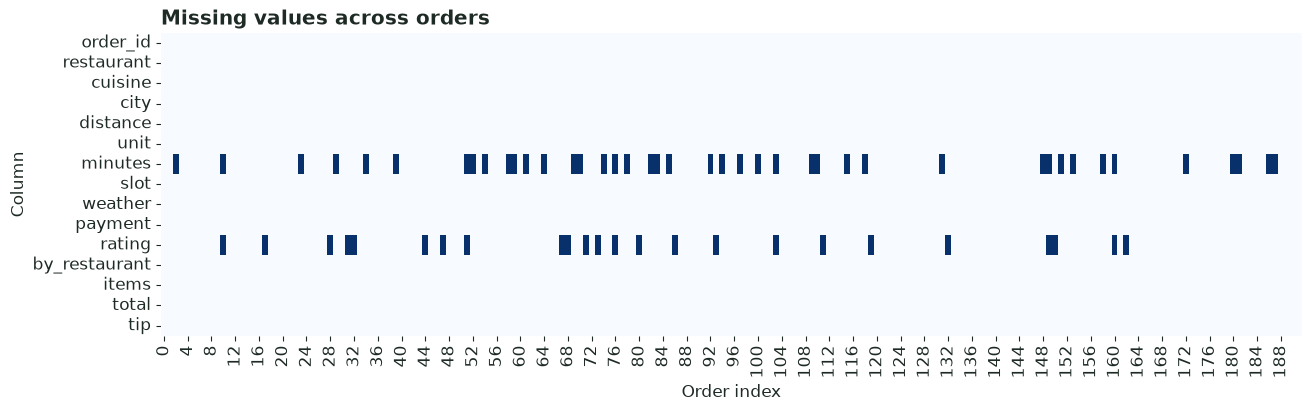

,missing_column,compared_with,p_value,adjusted_p_value,significant
4,minutes,by_restaurant,2.849549e-16,2.849549e-15,True
0,minutes,city,4.732282e-01,1.000000e+00,False
2,minutes,weather,1.000000e+00,1.000000e+00,False
1,minutes,slot,8.911425e-01,1.000000e+00,False
3,minutes,payment,4.038386e-01,1.000000e+00,False
5,rating,city,2.285110e-01,1.000000e+00,False
6,rating,slot,6.235426e-01,1.000000e+00,False
7,rating,weather,1.224495e-01,1.000000e+00,False
8,rating,payment,6.233909e-01,1.000000e+00,False
9,rating,by_restaurant,1.000000e+00,1.000000e+00,False



Missing minutes by slot:


slot
Lunch         19.64
Dinner        22.78
Late night    22.81
Name: missing_percent, dtype: float64


Missing minutes by weather:


weather
Clear    21.64
Rain     22.41
Name: missing_percent, dtype: float64

...

slot
Lunch         16.07
Dinner        11.39
Late night    10.53
Name: missing_percent, dtype: float64


Missing rating by weather:


weather
Clear     9.70
Rain     18.97
Name: missing_percent, dtype: float64


Missing rating by city:


city
Bitola       0.00
Kumanovo     9.09
Ohrid       20.00
Prilep      28.57
Skopje      12.12
Tetovo      12.50
Name: missing_percent, dtype: float64

In [37]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

display(missing_summary)

plt.figure(figsize=(13, 4))
sns.heatmap(df.isna().T, cmap="Blues", cbar=False)
plt.title("Missing values across orders")
plt.xlabel("Order index")
plt.ylabel("Column")
plt.show()

results = []

for target in ["minutes", "rating"]:
    for feature in ["city", "slot", "weather", "payment", "by_restaurant"]:
        contingency = pd.crosstab(df[feature], df[target].isna())

        if contingency.shape[0] > 1 and contingency.shape[1] == 2:
            chi2, p_value, dof, expected = stats.chi2_contingency(contingency)

            results.append({
                "missing_column": target,
                "compared_with": feature,
                "p_value": p_value
            })

missing_tests = pd.DataFrame(results)
missing_tests["adjusted_p_value"] = multipletests(
    missing_tests["p_value"],
    method="holm"
)[1]

missing_tests["significant"] = missing_tests["adjusted_p_value"] < 0.05

display(missing_tests.sort_values("adjusted_p_value"))

for target in ["minutes", "rating"]:
    for feature in ["slot", "weather", "city"]:
        print(f"\nMissing {target} by {feature}:")
        display(
            df.groupby(feature, observed=True)[target]
            .apply(lambda x: round(x.isna().mean() * 100, 2))
            .rename("missing_percent")
        )

### 3.3 Distances in Two Units

Some orders quote the distance in metres and others in kilometres. Compare the quoted distances within each unit, then add a column `distance_km` that states every distance in kilometres.

,count,mean,std,min,25%,50%,75%,max
unit,,,,,,,,
km,162.0,3.230247,1.276013,1.3,2.3,2.9,4.1,8.0
m,30.0,2498.333333,1066.777562,1200.0,1650.0,2375.0,2887.5,5350.0


Distance in kilometres:


,distance,unit,distance_km
0,5.0,km,5.00
1,3650.0,m,3.65
2,4700.0,m,4.70
3,2.7,km,2.70
4,2.4,km,2.40
5,3.6,km,3.60
6,3.2,km,3.20
7,1.7,km,1.70
8,3.9,km,3.90
9,4450.0,m,4.45


Summary of distance_km:


count    192.000000
mean       3.115885
std        1.271319
min        1.200000
25%        2.200000
50%        2.825000
75%        4.000000
max        8.000000
Name: distance_km, dtype: float64

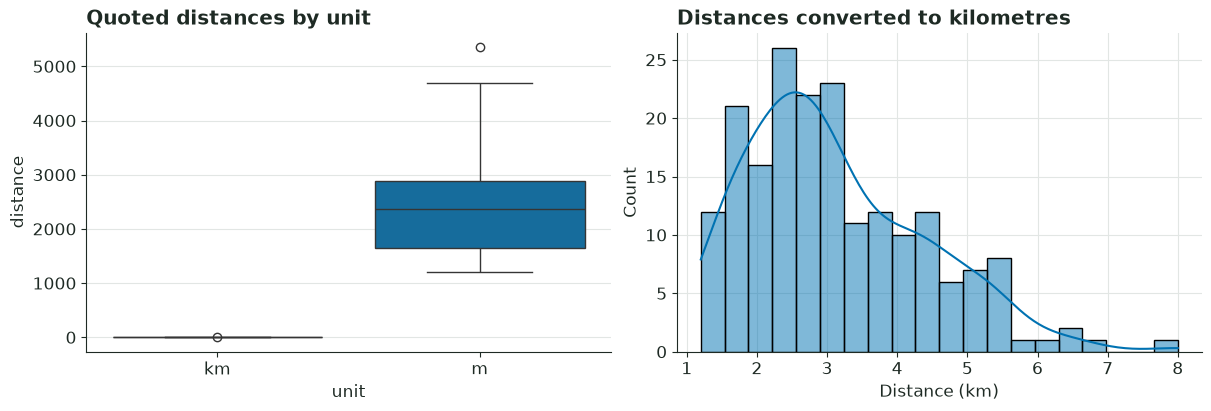

In [38]:
distance_by_unit = df.groupby("unit", observed=True)["distance"].describe()

display(distance_by_unit)

df["distance_km"] = np.where(
    df["unit"].eq("m"),
    df["distance"] / 1000,
    df["distance"]
)

print("Distance in kilometres:")
display(df[["distance", "unit", "distance_km"]].head(10))

print("Summary of distance_km:")
display(df["distance_km"].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="unit", y="distance", ax=axes[0])
axes[0].set_title("Quoted distances by unit")

sns.histplot(df["distance_km"], bins=20, kde=True, ax=axes[1])
axes[1].set_title("Distances converted to kilometres")
axes[1].set_xlabel("Distance (km)")

plt.show()

### 3.4 The Delivery Time

Describe the delivery time by its centre, its spread, and the shape of its distribution, and show the distribution. Decide which summary of the centre describes a typical order better.

Count: 150
Mean: 29.78
Median: 27.0
Standard deviation: 10.28
Variance: 105.76
Minimum: 12.0
Maximum: 72.0
Q1: 23.0
Q3: 34.0
IQR: 11.0
Skewness: 1.412
Outliers: 9


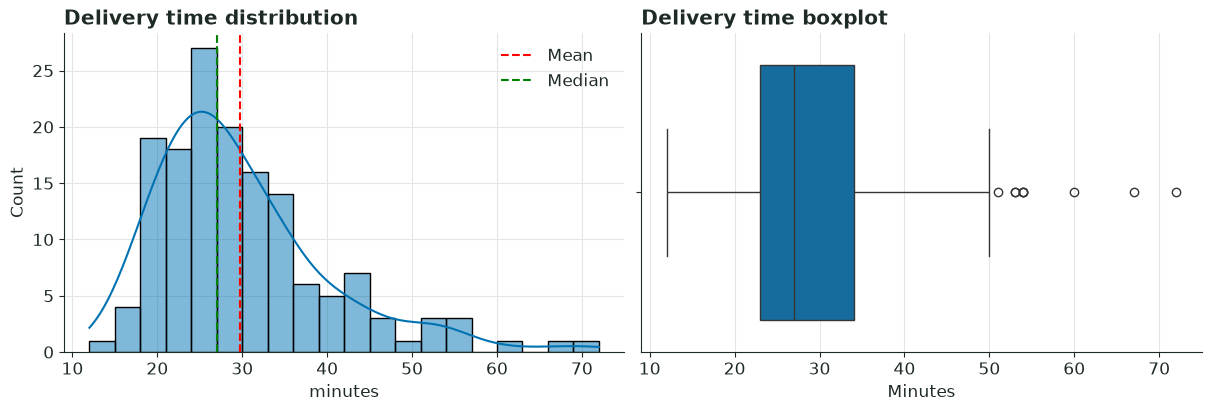

Better measure of a typical delivery: Median


In [39]:
delivery_times = df["minutes"].dropna()

q1 = delivery_times.quantile(0.25)
q3 = delivery_times.quantile(0.75)
iqr = q3 - q1

outliers = delivery_times[
    (delivery_times < q1 - 1.5 * iqr) |
    (delivery_times > q3 + 1.5 * iqr)
]

print("Count:", len(delivery_times))
print("Mean:", round(delivery_times.mean(), 2))
print("Median:", round(delivery_times.median(), 2))
print("Standard deviation:", round(delivery_times.std(), 2))
print("Variance:", round(delivery_times.var(), 2))
print("Minimum:", delivery_times.min())
print("Maximum:", delivery_times.max())
print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Skewness:", round(stats.skew(delivery_times), 3))
print("Outliers:", len(outliers))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(delivery_times, bins=20, kde=True, ax=axes[0])
axes[0].axvline(delivery_times.mean(), color="red", linestyle="--", label="Mean")
axes[0].axvline(delivery_times.median(), color="green", linestyle="--", label="Median")
axes[0].legend()
axes[0].set_title("Delivery time distribution")

sns.boxplot(x=delivery_times, ax=axes[1])
axes[1].set_title("Delivery time boxplot")
axes[1].set_xlabel("Minutes")

plt.show()

typical = "Median" if abs(stats.skew(delivery_times)) > 0.5 or len(outliers) > 0 else "Mean"
print("Better measure of a typical delivery:", typical)

### 3.5 Delivery Time by Slot

Compare the delivery time across the slots.

,count,mean,median,std,minimum,maximum
slot,,,,,,
Lunch,45,28.93,27.0,9.61,12.0,54.0
Dinner,61,30.75,28.0,9.50,16.0,54.0
Late night,44,29.30,26.0,11.99,17.0,72.0


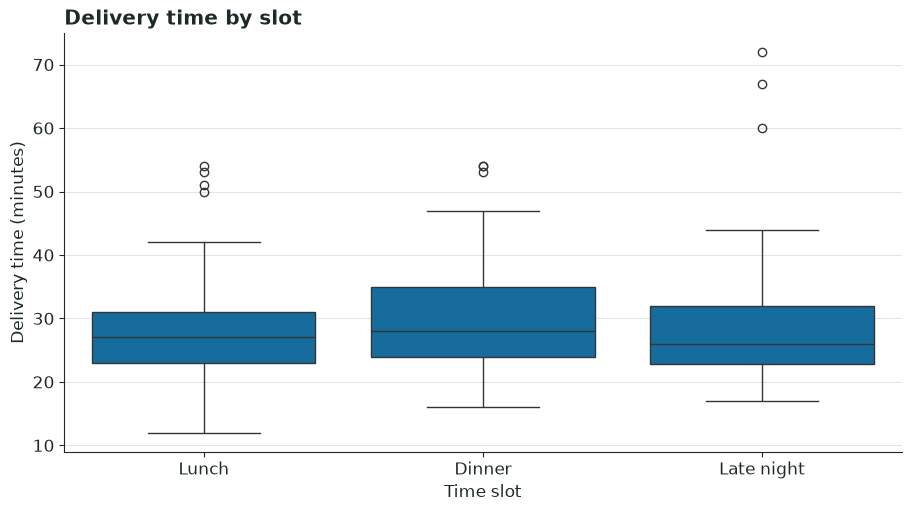

Slot with highest median delivery time:
Dinner


In [40]:
slot_summary = df.groupby("slot", observed=True)["minutes"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    minimum="min",
    maximum="max"
)

display(slot_summary.round(2))

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="slot", y="minutes", order=["Lunch", "Dinner", "Late night"])
plt.title("Delivery time by slot")
plt.xlabel("Time slot")
plt.ylabel("Delivery time (minutes)")
plt.show()

print("Slot with highest median delivery time:")
print(slot_summary["median"].idxmax())

### 3.6 Orders by City

Show how the orders are spread across the cities, and give the share of orders in each city.

,orders,share_percent
city,,
Skopje,99,51.56
Tetovo,24,12.50
Kumanovo,22,11.46
Bitola,18,9.38
Ohrid,15,7.81
Prilep,14,7.29


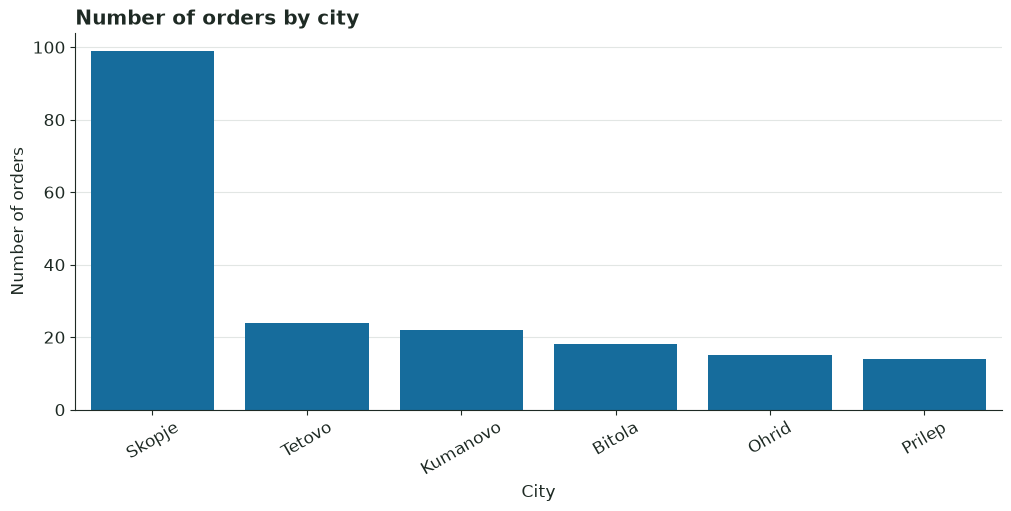

Total share: 100.0 %


In [41]:
city_counts = df["city"].value_counts()

city_summary = pd.DataFrame({
    "orders": city_counts,
    "share_percent": (city_counts / len(df) * 100).round(2)
})

display(city_summary)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=city_summary.index.astype(str),
    y=city_summary["orders"].to_numpy()
)
plt.title("Number of orders by city")
plt.xlabel("City")
plt.ylabel("Number of orders")
plt.xticks(rotation=30)
plt.show()

print("Total share:", round(city_summary["share_percent"].sum(), 2), "%")

### 3.7 Items and Total

Show how the number of items and the total of an order move together, and measure how strongly they do. Decide whether the relationship is close to a straight line.

Pearson correlation: 0.8806
Pearson p-value: 1.6001635285759119e-63
Spearman correlation: 0.8691
Spearman p-value: 5.354922949213422e-60
R-squared: 0.7754
Regression equation: total = 1.66 + 291.71 * items


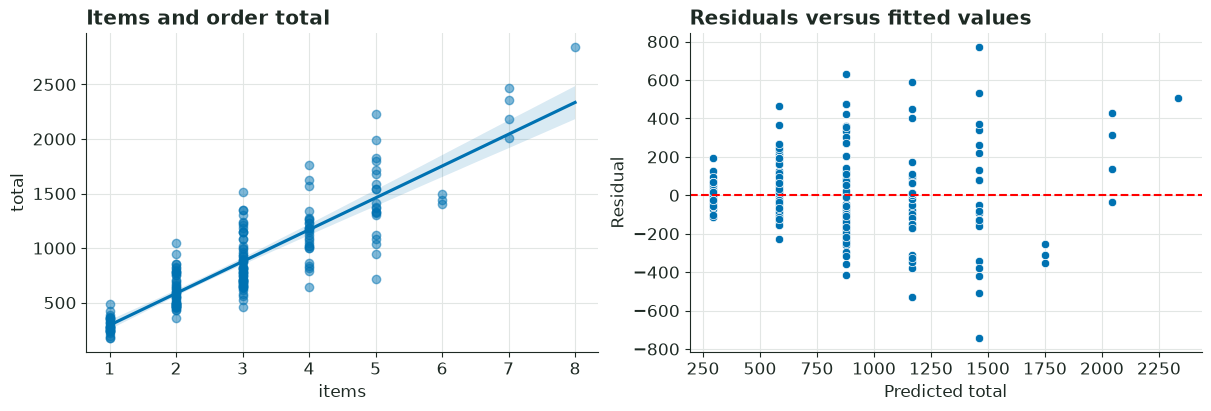

Close to a straight-line relationship: True


In [42]:
items_total = df[["items", "total"]].dropna().astype(float)

pearson_r, pearson_p = stats.pearsonr(
    items_total["items"],
    items_total["total"]
)

spearman_r, spearman_p = stats.spearmanr(
    items_total["items"],
    items_total["total"]
)

slope, intercept, r_value, p_value, std_err = stats.linregress(
    items_total["items"],
    items_total["total"]
)

print("Pearson correlation:", round(pearson_r, 4))
print("Pearson p-value:", pearson_p)
print("Spearman correlation:", round(spearman_r, 4))
print("Spearman p-value:", spearman_p)
print("R-squared:", round(r_value ** 2, 4))
print("Regression equation: total =", round(intercept, 2), "+", round(slope, 2), "* items")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.regplot(
    data=items_total,
    x="items",
    y="total",
    ax=axes[0],
    scatter_kws={"alpha": 0.5}
)
axes[0].set_title("Items and order total")

predicted = intercept + slope * items_total["items"]
residuals = items_total["total"] - predicted

sns.scatterplot(x=predicted, y=residuals, ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals versus fitted values")
axes[1].set_xlabel("Predicted total")
axes[1].set_ylabel("Residual")

plt.show()

print("Close to a straight-line relationship:", abs(pearson_r) >= 0.8)

### 3.8 Every Pair of Numeric Columns

Show how strongly every pair of numeric columns moves together, measured by the Spearman correlation, and name the pair that moves together most strongly.

,distance,minutes,rating,items,total,tip,distance_km
distance,1.000,0.297,-0.201,-0.023,-0.038,0.011,0.578
minutes,0.297,1.000,-0.415,-0.066,-0.036,0.071,0.590
rating,-0.201,-0.415,1.000,0.082,0.088,-0.041,-0.309
items,-0.023,-0.066,0.082,1.000,0.869,0.423,-0.005
total,-0.038,-0.036,0.088,0.869,1.000,0.463,0.003
tip,0.011,0.071,-0.041,0.423,0.463,1.000,0.021
distance_km,0.578,0.590,-0.309,-0.005,0.003,0.021,1.000


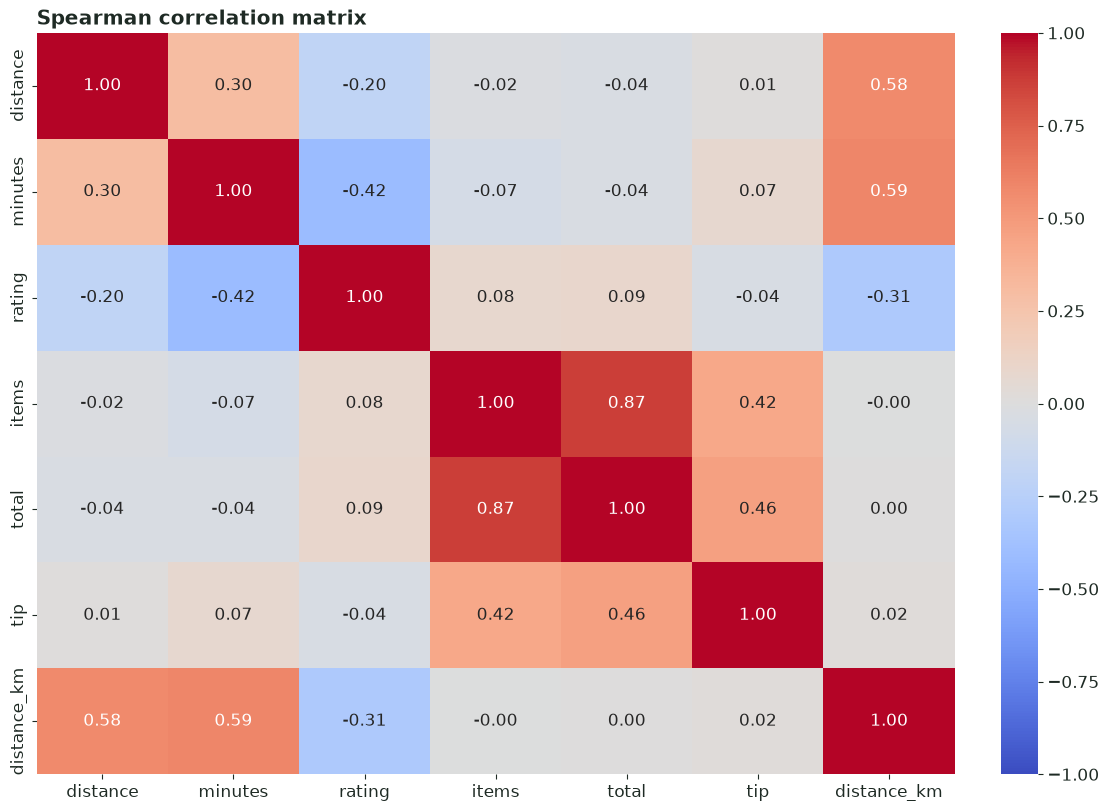

,column_1,column_2,correlation,absolute_correlation
25,items,total,0.869127,0.869127
13,minutes,distance_km,0.589610,0.589610
6,distance,distance_km,0.578082,0.578082
33,total,tip,0.463362,0.463362
26,items,tip,0.422834,0.422834
9,minutes,rating,-0.415339,0.415339
20,rating,distance_km,-0.309499,0.309499
1,distance,minutes,0.297366,0.297366
2,distance,rating,-0.201275,0.201275
18,rating,total,0.088289,0.088289


Strongest pair: items and total
Spearman correlation: 0.8691


In [43]:
numeric_df = df.select_dtypes(include="number").drop(
    columns=["order_id"],
    errors="ignore"
)

correlation_matrix = numeric_df.corr(method="spearman")

display(correlation_matrix.round(3))

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Spearman correlation matrix")
plt.show()

mask = np.triu(np.ones(correlation_matrix.shape, dtype=bool), k=1)

correlation_pairs = (
    correlation_matrix.where(mask)
    .stack()
    .rename("correlation")
    .reset_index()
)

correlation_pairs.columns = ["column_1", "column_2", "correlation"]
correlation_pairs["absolute_correlation"] = correlation_pairs["correlation"].abs()

correlation_pairs = correlation_pairs.sort_values(
    "absolute_correlation",
    ascending=False
)

display(correlation_pairs)

strongest_pair = correlation_pairs.iloc[0]

print("Strongest pair:", strongest_pair["column_1"], "and", strongest_pair["column_2"])
print("Spearman correlation:", round(strongest_pair["correlation"], 4))

### 3.9 Delivery Time by City and Slot

Find the combination of city and slot with the highest median delivery time, counting only the combinations with at least three orders that state a delivery time.

,city,slot,count,median,mean
10,Prilep,Dinner,5,35.0,33.200000
15,Tetovo,Lunch,3,34.0,36.666667
4,Kumanovo,Dinner,6,33.5,31.833333
17,Tetovo,Late night,5,32.0,37.400000
8,Ohrid,Late night,3,32.0,40.666667
3,Kumanovo,Lunch,8,29.5,35.000000
16,Tetovo,Dinner,8,29.5,31.750000
0,Bitola,Lunch,4,28.5,32.500000
13,Skopje,Dinner,35,28.0,29.828571
9,Prilep,Lunch,3,27.0,32.000000


City: Prilep
Slot: Dinner
Median delivery time: 35.0
Orders with delivery time: 5


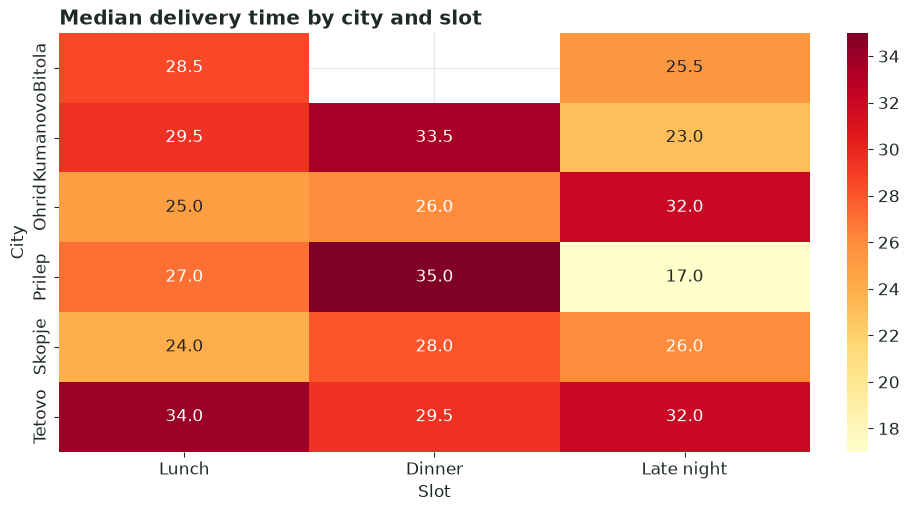

In [44]:
city_slot_summary = (
    df.groupby(["city", "slot"], observed=True)["minutes"]
    .agg(count="count", median="median", mean="mean")
    .reset_index()
)

valid_combinations = (
    city_slot_summary[city_slot_summary["count"] >= 3]
    .sort_values(["median", "count"], ascending=[False, False])
)

display(valid_combinations)

highest = valid_combinations.iloc[0]

print("City:", highest["city"])
print("Slot:", highest["slot"])
print("Median delivery time:", highest["median"])
print("Orders with delivery time:", highest["count"])

pivot_medians = valid_combinations.pivot(
    index="city",
    columns="slot",
    values="median"
)

plt.figure(figsize=(9, 5))
sns.heatmap(pivot_medians, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Median delivery time by city and slot")
plt.xlabel("Slot")
plt.ylabel("City")
plt.show()

## Task 4: Delivery Times

Use a significance level of 5 % and a confidence level of 95 % for every decision and every range in this task and the next. For each question, state the decision and give the range beside it. The questions of this task concern the orders that state a delivery time.

### 4.1 The Advertised Time

The home page states an average delivery time. Decide whether the average delivery time of the orders differs from that statement, and give a range for the average delivery time.

In [45]:
advertised_mean = 28
delivery_times = df["minutes"].dropna()

n = len(delivery_times)
sample_mean = delivery_times.mean()
sample_std = delivery_times.std(ddof=1)
standard_error = stats.sem(delivery_times)

t_statistic, p_value = stats.ttest_1samp(
    delivery_times,
    popmean=advertised_mean
)

confidence_interval = stats.t.interval(
    confidence=0.95,
    df=n - 1,
    loc=sample_mean,
    scale=standard_error
)

print("Advertised average:", advertised_mean)
print("Sample size:", n)
print("Sample mean:", round(sample_mean, 3))
print("Sample standard deviation:", round(sample_std, 3))
print("T-statistic:", round(t_statistic, 4))
print("P-value:", p_value)
print("95% confidence interval:", tuple(round(x, 3) for x in confidence_interval))

if p_value < 0.05:
    print("Decision: Reject H0. The average delivery time differs from 28 minutes.")
else:
    print("Decision: Do not reject H0. There is insufficient evidence of a difference.")

Advertised average: 28
Sample size: 150
Sample mean: 29.78
Sample standard deviation: 10.284
T-statistic: 2.1199
P-value: 0.035672962210614674
95% confidence interval: (np.float64(28.121), np.float64(31.439))
Decision: Reject H0. The average delivery time differs from 28 minutes.


### 4.2 Rain and Clear Weather

Decide whether the orders delivered in rain and in clear weather differ in their average delivery time, and give a range for the difference, taken as rain minus clear.

In [46]:
rain = df.loc[df["weather"] == "Rain", "minutes"].dropna()
clear = df.loc[df["weather"] == "Clear", "minutes"].dropna()

n_rain = len(rain)
n_clear = len(clear)

mean_rain = rain.mean()
mean_clear = clear.mean()

var_rain = rain.var(ddof=1)
var_clear = clear.var(ddof=1)

mean_difference = mean_rain - mean_clear

t_statistic, p_value = stats.ttest_ind(
    rain,
    clear,
    equal_var=False
)

standard_error = np.sqrt(
    var_rain / n_rain + var_clear / n_clear
)

welch_df = (
    (var_rain / n_rain + var_clear / n_clear) ** 2
    /
    (
        (var_rain / n_rain) ** 2 / (n_rain - 1)
        +
        (var_clear / n_clear) ** 2 / (n_clear - 1)
    )
)

confidence_interval = stats.t.interval(
    confidence=0.95,
    df=welch_df,
    loc=mean_difference,
    scale=standard_error
)

print("Rain orders:", n_rain)
print("Clear orders:", n_clear)
print("Mean in rain:", round(mean_rain, 3))
print("Mean in clear weather:", round(mean_clear, 3))
print("Difference (rain - clear):", round(mean_difference, 3))
print("T-statistic:", round(t_statistic, 4))
print("P-value:", p_value)
print("95% confidence interval:", tuple(round(x, 3) for x in confidence_interval))

if p_value < 0.05:
    print("Decision: Reject H0. Mean delivery times differ between rain and clear weather.")
else:
    print("Decision: Do not reject H0. There is insufficient evidence of a difference.")

Rain orders: 45
Clear orders: 105
Mean in rain: 32.778
Mean in clear weather: 28.495
Difference (rain - clear): 4.283
T-statistic: 2.196
P-value: 0.031371648323607615
95% confidence interval: (np.float64(0.394), np.float64(8.171))
Decision: Reject H0. Mean delivery times differ between rain and clear weather.


## Task 5: Slots and Payments

The questions of this task concern all orders.

### 5.1 Payment by Slot

Decide whether the payment method depends on the slot of an order, and give a range for the share of cash payments in each slot, using a percentile bootstrap.

payment,Card,Cash
slot,,
Lunch,49,7
Dinner,57,22
Late night,34,23


Chi-square statistic: 11.1349
Degrees of freedom: 2
P-value: 0.003820197333558141
Expected frequencies:


payment,Card,Cash
slot,,
Lunch,40.83,15.17
Dinner,57.60,21.40
Late night,41.56,15.44


Decision: Reject H0. Payment method depends on the time slot.


,slot,orders,cash_share,ci_lower,ci_upper
0,Lunch,56,0.1250,0.0536,0.2143
1,Dinner,79,0.2785,0.1899,0.3797
2,Late night,57,0.4035,0.2807,0.5263


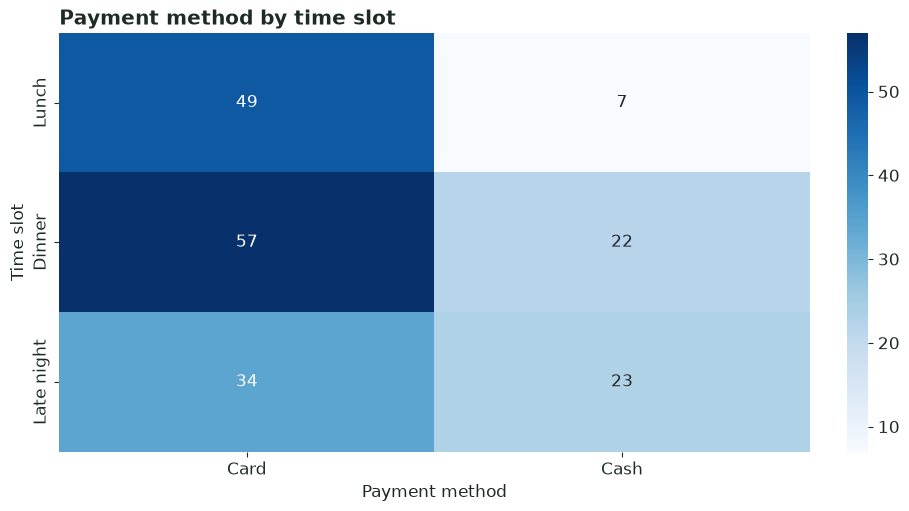

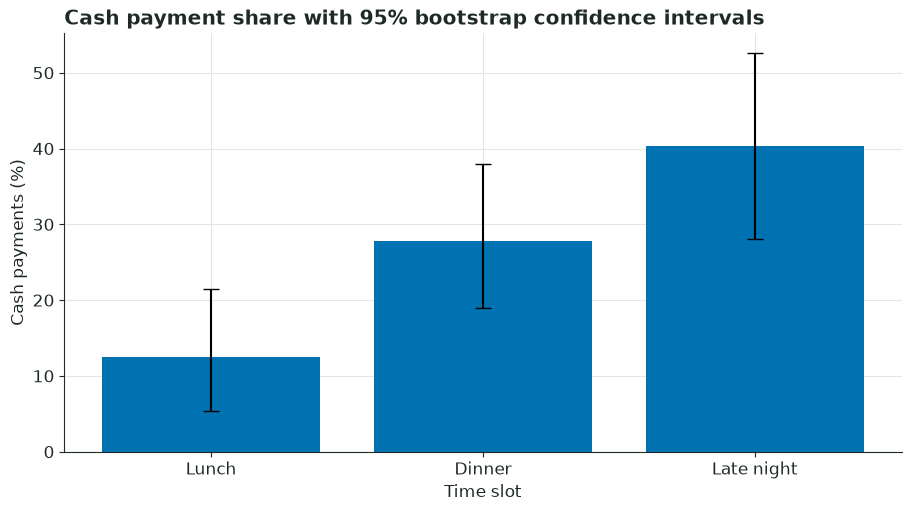

In [47]:
payment_table = pd.crosstab(df["slot"], df["payment"])

display(payment_table)

chi2, p_value, dof, expected = stats.chi2_contingency(payment_table)

print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("P-value:", p_value)

expected_table = pd.DataFrame(
    expected,
    index=payment_table.index,
    columns=payment_table.columns
)

print("Expected frequencies:")
display(expected_table.round(2))

if p_value < 0.05:
    print("Decision: Reject H0. Payment method depends on the time slot.")
else:
    print("Decision: Do not reject H0. There is insufficient evidence of dependence.")

bootstrap_results = []

for slot in ["Lunch", "Dinner", "Late night"]:
    payments = df.loc[df["slot"] == slot, "payment"].dropna()
    cash_values = payments.eq("Cash").to_numpy(dtype=int)

    bootstrap_samples = rng.choice(
        cash_values,
        size=(10000, len(cash_values)),
        replace=True
    )

    bootstrap_shares = bootstrap_samples.mean(axis=1)

    lower, upper = np.percentile(
        bootstrap_shares,
        [2.5, 97.5]
    )

    bootstrap_results.append({
        "slot": slot,
        "orders": len(cash_values),
        "cash_share": cash_values.mean(),
        "ci_lower": lower,
        "ci_upper": upper
    })

cash_bootstrap = pd.DataFrame(bootstrap_results)

display(cash_bootstrap.round(4))

plt.figure(figsize=(9, 5))

sns.heatmap(
    payment_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Payment method by time slot")
plt.xlabel("Payment method")
plt.ylabel("Time slot")
plt.show()

plt.figure(figsize=(9, 5))

positions = np.arange(len(cash_bootstrap))

plt.bar(
    positions,
    cash_bootstrap["cash_share"] * 100,
    yerr=[
        (cash_bootstrap["cash_share"] - cash_bootstrap["ci_lower"]) * 100,
        (cash_bootstrap["ci_upper"] - cash_bootstrap["cash_share"]) * 100
    ],
    capsize=6
)

plt.xticks(positions, cash_bootstrap["slot"])
plt.ylabel("Cash payments (%)")
plt.xlabel("Time slot")
plt.title("Cash payment share with 95% bootstrap confidence intervals")
plt.show()

### 5.2 The Mix of Slots

The home page states how the orders divide among the slots. Decide whether the orders match that statement, and give a range for the share of late-night orders, using a percentile bootstrap.

,observed_count,expected_count,observed_share,advertised_share
slot,,,,
Lunch,56,67.2,0.2917,0.35
Dinner,79,86.4,0.4115,0.45
Late night,57,38.4,0.2969,0.20


Chi-square statistic: 11.5098
Degrees of freedom: 2
P-value: 0.0031671631995379436
Decision: Reject H0. The slot distribution differs from the advertised proportions.
Late-night share: 0.2969
95% bootstrap confidence interval: (np.float64(0.2344), np.float64(0.3646))


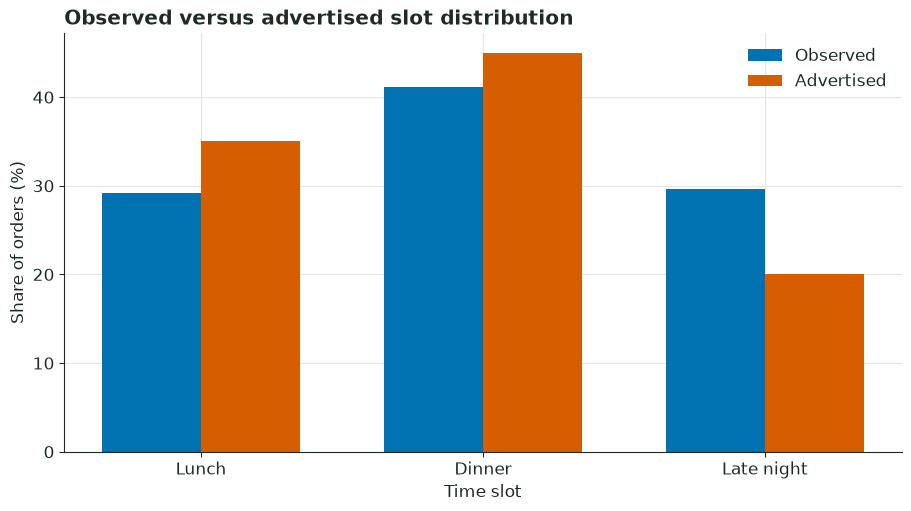

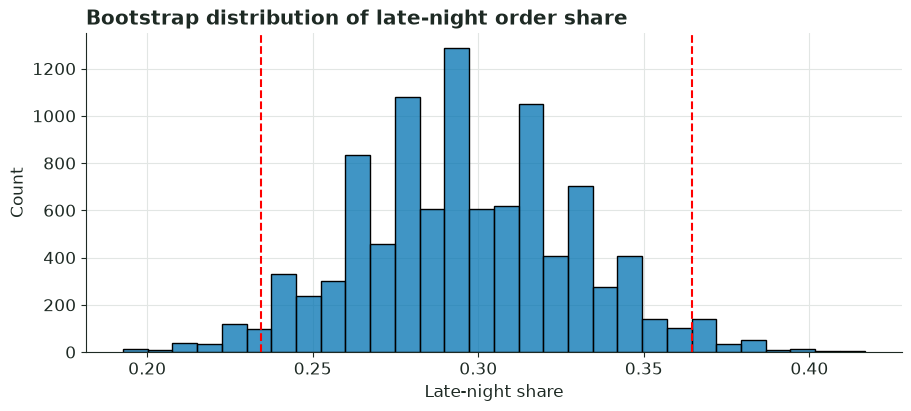

In [48]:
slots = ["Lunch", "Dinner", "Late night"]

advertised_proportions = np.array([0.35, 0.45, 0.20])

observed_counts = df["slot"].value_counts().reindex(
    slots,
    fill_value=0
)

total_orders = observed_counts.sum()
expected_counts = total_orders * advertised_proportions

chi2, p_value = stats.chisquare(
    f_obs=observed_counts.to_numpy(),
    f_exp=expected_counts
)

slot_mix = pd.DataFrame({
    "observed_count": observed_counts,
    "expected_count": expected_counts,
    "observed_share": observed_counts / total_orders,
    "advertised_share": advertised_proportions
})

display(slot_mix.round(4))

print("Chi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", len(slots) - 1)
print("P-value:", p_value)

if p_value < 0.05:
    print("Decision: Reject H0. The slot distribution differs from the advertised proportions.")
else:
    print("Decision: Do not reject H0. There is insufficient evidence of a difference.")

late_night_values = df["slot"].eq("Late night").to_numpy(dtype=int)

bootstrap_samples = rng.choice(
    late_night_values,
    size=(10000, len(late_night_values)),
    replace=True
)

bootstrap_shares = bootstrap_samples.mean(axis=1)

lower, upper = np.percentile(
    bootstrap_shares,
    [2.5, 97.5]
)

print("Late-night share:", round(late_night_values.mean(), 4))
print("95% bootstrap confidence interval:", (round(lower, 4), round(upper, 4)))

x = np.arange(len(slots))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    slot_mix["observed_share"] * 100,
    width,
    label="Observed"
)

plt.bar(
    x + width / 2,
    slot_mix["advertised_share"] * 100,
    width,
    label="Advertised"
)

plt.xticks(x, slots)
plt.xlabel("Time slot")
plt.ylabel("Share of orders (%)")
plt.title("Observed versus advertised slot distribution")
plt.legend()
plt.show()

plt.figure(figsize=(9, 4))
sns.histplot(bootstrap_shares, bins=30)
plt.axvline(lower, color="red", linestyle="--")
plt.axvline(upper, color="red", linestyle="--")
plt.title("Bootstrap distribution of late-night order share")
plt.xlabel("Late-night share")
plt.show()

In [27]:
server.shutdown()